# GNN-based Graph Clustering (VGAE + KMeans) — CPU, extended experiments

This notebook extends the original CPU notebook with:

- the original **VGAE + KMeans baseline** on all four datasets;
- a compact **hyperparameter sweep** to show what different settings do;
- an **ablation study** covering the KL term, node-feature choice, and a no-GNN KMeans baseline;
- clearer **3-D latent-space visualizations**, with predicted clusters aligned to ground-truth labels for easier visual comparison;
- graph/data diagnostics and a **report-ready interpretation** of the key factors affecting performance;
- CSV exports for the baseline, sweep, ablation, graph statistics, and a combined experiment table.

The notebook remains CPU-only and keeps the original result columns (`NMI`, `ARI`, `modularity`, etc.) so the baseline can still be merged with the Louvain/Leiden results.

> **Important:** the extended experiments are designed to be reproducible but are intentionally compact so they remain practical on a laptop CPU. Use the controls in Section 2 to increase epochs/repeats when you have more runtime available.


## 1. What the GNN is doing

The model is a **Variational Graph Autoencoder (VGAE)** with a two-layer GCN encoder.

For every node, the GCN maps its input features and local graph neighbourhood into a latent distribution. A sampled latent embedding is then trained to reconstruct observed graph edges. After training, **KMeans is applied to the learned node embeddings** to obtain communities.

### Strengths

1. **Uses graph structure directly.** Neighbourhood aggregation lets a node's representation depend on its local topology rather than treating nodes as independent observations.
2. **Can combine topology and node attributes.** Cora has text-derived features, while the original notebook uses degree as a fallback for the other datasets.
3. **Unsupervised representation learning.** Ground-truth community labels are not used for training; they are only used afterward for NMI/ARI evaluation.
4. **Reusable embeddings.** The latent vectors can support clustering or other downstream tasks.

### Weaknesses / limitations

1. **The training objective is edge reconstruction, not community recovery.** A representation can reconstruct edges well without producing community boundaries that align with the evaluation labels.
2. **KMeans needs `K` in advance.** Here `K` is set to the true number of communities so the results are directly comparable to the original notebook; this gives the GNN pipeline information that fully unsupervised community detection methods do not require.
3. **Feature quality matters.** Weak or uninformative node features can limit the usefulness of the encoder. For datasets without natural features, degree is only a 1-D proxy.
4. **Hyperparameters and random initialization matter.** Hidden width, latent dimension, learning rate, KL weight, training duration, and KMeans initialization can all change the final clustering.
5. **Depth and graph size are practical concerns.** Deeper GCNs can suffer from over-smoothing, while larger graphs increase training cost. This notebook therefore stays with a shallow encoder and CPU-friendly experiments.
6. **The largest-connected-component preprocessing discards disconnected nodes.** This is retained for consistency with the original experiment and should be mentioned when interpreting results.

These are methodological considerations; the sweep and ablation sections below are included to test which of them are most visible on the supplied datasets.


## 2. Experiment controls

The defaults below keep the CPU workload moderate. The baseline is run on all four datasets. The extended sweep and ablation can be switched on/off independently.

Recommended starting values on a laptop:
- baseline: 100 epochs;
- hyperparameter sweep: 60 epochs per configuration;
- 1 seed per configuration.

For a more rigorous study, set `EXTRA_REPEATS = 3` or `5` and report mean ± standard deviation.


In [1]:

# -----------------------------
# User-adjustable experiment controls
# -----------------------------
SEED = 67
BASELINE_EPOCHS = 100
BASELINE_LR = 0.01
BASELINE_HIDDEN = 32
BASELINE_LATENT = 16
BASELINE_KL_WEIGHT = 1.0
BASELINE_DROPOUT = 0.0
KMEANS_N_INIT = 10

RUN_HYPERPARAMETER_SWEEP = True
RUN_ABLATION = True

# The sweep is one-factor-at-a-time on one reference dataset to stay CPU-friendly.
SWEEP_DATASET = "lfr-easy"
SWEEP_EPOCHS = 60
SWEEP_REPEATS = 1

# Set >1 for a more stable study. Runtime scales approximately linearly.
EXTRA_REPEATS = 1

# 3-D projection method: "pca" is fast and deterministic given the learned embedding.
# "tsne" is more non-linear but slower and less directly interpretable.
PROJECTION_METHOD = "pca"

SAVE_FIGURES = True
FIGURE_DIR = "gnn_figures"

print({
    "baseline_epochs": BASELINE_EPOCHS,
    "sweep_dataset": SWEEP_DATASET,
    "sweep_epochs": SWEEP_EPOCHS,
    "run_sweep": RUN_HYPERPARAMETER_SWEEP,
    "run_ablation": RUN_ABLATION,
    "extra_repeats": EXTRA_REPEATS,
})


{'baseline_epochs': 100, 'sweep_dataset': 'lfr-easy', 'sweep_epochs': 60, 'run_sweep': True, 'run_ablation': True, 'extra_repeats': 1}


In [2]:

# Install CPU-compatible PyG if needed. If your environment already has the packages,
# the installs can be skipped/commented out.
import torch
print("torch:", torch.__version__, "| CUDA available:", torch.cuda.is_available())

!pip install -q torch_geometric


torch: 2.8.0+cpu | CUDA available: False


In [3]:

import os
import sys
import time
import copy
import random
import pickle as pkl
from pathlib import Path

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

import torch
import torch.nn.functional as F
from torch_geometric.utils import from_networkx
from torch_geometric.nn import GCNConv, VGAE

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import (
    normalized_mutual_info_score,
    adjusted_rand_score,
    confusion_matrix,
)
from sklearn.preprocessing import StandardScaler

from scipy.optimize import linear_sum_assignment
import networkx.algorithms.community as nx_comm

# Same dataset-script location expected by the original notebook.
SCRIPTS_DIR = os.path.abspath("../Datasets/")
print("Dataset scripts:", SCRIPTS_DIR)
sys.path.append(SCRIPTS_DIR)

from graph_datasets import LOADERS, largest_component, summarise

device = torch.device("cpu")
print("Using device:", device)

def seed_everything(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

seed_everything(SEED)
Path(FIGURE_DIR).mkdir(exist_ok=True)


c:\Users\josqu\AppData\Local\Programs\Python\Python312\Lib\site-packages\torch_geometric\__init__.py:4: UserWarning: An issue occurred while importing 'pyg-lib'. Disabling its usage. Stacktrace: Could not find module 'C:\Users\josqu\AppData\Local\Programs\Python\Python312\Lib\site-packages\libpyg.pyd' (or one of its dependencies). Try using the full path with constructor syntax.
  import torch_geometric.typing
c:\Users\josqu\AppData\Local\Programs\Python\Python312\Lib\site-packages\torch_geometric\__init__.py:4: UserWarning: An issue occurred while importing 'torch-scatter'. Disabling its usage. Stacktrace: [WinError 127] The specified procedure could not be found
  import torch_geometric.typing
c:\Users\josqu\AppData\Local\Programs\Python\Python312\Lib\site-packages\torch_geometric\__init__.py:4: UserWarning: An issue occurred while importing 'torch-cluster'. Disabling its usage. Stacktrace: [WinError 127] The specified procedure could not be found
  import torch_geometric.typing
c:\U

Dataset scripts: c:\Users\josqu\OneDrive - Nanyang Technological University\School Documents\Y3S1\SC4020 - Data Analytics and Mining\Project\SC4020-DataMining\Datasets
Using device: cpu


## 3. Load datasets and prepare features

The original feature policy is preserved:

- **Cora:** use the original Planetoid text features when they align with the graph; otherwise fall back to degree.
- **email-eu-core / LFR:** use node degree as the 1-D feature.

For the ablation study, the notebook also supports:
- `feature_mode="native"` — original feature policy;
- `feature_mode="degree"` — degree-only for every dataset;
- `feature_mode="constant"` — a constant 1-D feature, so the GCN must rely on graph structure rather than degree differences.

The constant-feature condition is a structural ablation, not an assertion that constant features are generally useful.


In [4]:

def load_cora_native_features(G):
    """Load Cora Planetoid features when the row count matches the current graph."""
    raw_dir = os.path.join(SCRIPTS_DIR, "..", "data", "raw")
    try:
        with open(os.path.join(raw_dir, "ind.cora.allx"), "rb") as f:
            allx = pkl.load(f, encoding="latin1")
        with open(os.path.join(raw_dir, "ind.cora.tx"), "rb") as f:
            tx = pkl.load(f, encoding="latin1")
        import scipy.sparse as sp
        feat = sp.vstack((allx, tx)).toarray() if sp.issparse(allx) else np.vstack((allx, tx))
        if feat.shape[0] == G.number_of_nodes():
            return torch.tensor(feat, dtype=torch.float)
    except FileNotFoundError:
        pass
    return None


def build_pyg_data(name, G, y, feature_mode="native"):
    """Convert an (nx.Graph, label array) pair into a PyG Data object."""
    data = from_networkx(G)

    degree = np.array([d for _, d in G.degree()], dtype=np.float32).reshape(-1, 1)

    if feature_mode == "constant":
        x = torch.ones((G.number_of_nodes(), 1), dtype=torch.float)

    elif feature_mode == "degree":
        x = torch.tensor(degree, dtype=torch.float)

    elif feature_mode == "native":
        native = load_cora_native_features(G) if name == "cora" else None
        x = native if native is not None else torch.tensor(degree, dtype=torch.float)

    else:
        raise ValueError(f"Unknown feature_mode={feature_mode}")

    data.x = x
    data.y = torch.tensor(np.asarray(y), dtype=torch.long)
    return data


def load_dataset(name, feature_mode="native"):
    G, y = LOADERS[name]()
    G, y = largest_component(G, y)
    data = build_pyg_data(name, G, y, feature_mode=feature_mode)
    return G, np.asarray(y), data


datasets = {}
dataset_graphs = {}
dataset_labels = {}

for key in LOADERS:
    G, y, data = load_dataset(key, feature_mode="native")
    dataset_graphs[key] = G
    dataset_labels[key] = y
    datasets[key] = data
    print(summarise(key + " (LCC)", G, y))

print()
for k, d in datasets.items():
    print(f"{k:14s} -> x={tuple(d.x.shape)}, edges={d.edge_index.shape[1] // 2:,}")


C:\Users\josqu\AppData\Local\Temp\ipykernel_26432\3703914001.py:6: DeprecationWarning: Please import `csr_matrix` from the `scipy.sparse` namespace; the `scipy.sparse.csr` namespace is deprecated and will be removed in SciPy 2.0.0.
  allx = pkl.load(f, encoding="latin1")
C:\Users\josqu\AppData\Local\Temp\ipykernel_26432\3703914001.py:8: DeprecationWarning: Please import `csr_matrix` from the `scipy.sparse` namespace; the `scipy.sparse.csr` namespace is deprecated and will be removed in SciPy 2.0.0.
  tx = pkl.load(f, encoding="latin1")


cora (LCC)     n= 2485  m=  5069  communities=  7  unlabelled=   0  components=  1
email-eu-core (LCC) n=  986  m= 16064  communities= 42  unlabelled=   0  components=  1
lfr-easy (LCC) n= 1000  m=  8615  communities=  7  unlabelled=   0  components=  1
lfr-hard (LCC) n= 1000  m=  9053  communities=  6  unlabelled=   0  components=  1

cora           -> x=(2485, 1), edges=5,069
email-eu-core  -> x=(986, 1), edges=16,064
lfr-easy       -> x=(1000, 1), edges=8,615
lfr-hard       -> x=(1000, 1), edges=9,053


In [5]:

# Graph/data diagnostics used later to discuss key performance factors.
graph_stats = []
for key in LOADERS:
    G = dataset_graphs[key]
    y = dataset_labels[key]
    labeled = y[y >= 0]

    graph_stats.append({
        "dataset": key,
        "n_nodes": G.number_of_nodes(),
        "n_edges": G.number_of_edges(),
        "avg_degree": 2 * G.number_of_edges() / max(G.number_of_nodes(), 1),
        "density": nx.density(G),
        "avg_clustering": nx.average_clustering(G),
        "n_clusters": len(np.unique(labeled)),
        "labeled_fraction": float(np.mean(y >= 0)),
        "degree_std": float(np.std([d for _, d in G.degree()])),
    })

graph_stats_df = pd.DataFrame(graph_stats).sort_values("dataset").reset_index(drop=True)
display(graph_stats_df)
graph_stats_df.to_csv("gnn_graph_stats_cpu.csv", index=False)


,dataset,n_nodes,n_edges,avg_degree,density,avg_clustering,n_clusters,labeled_fraction,degree_std
0,cora,2485,5069,4.079678,0.001642,0.237636,7,1.0,5.405274
1,email-eu-core,986,16064,32.584178,0.033080,0.407050,42,1.0,37.025504
2,lfr-easy,1000,8615,17.230000,0.017247,0.170925,7,1.0,19.495823
3,lfr-hard,1000,9053,18.106000,0.018124,0.108334,6,1.0,25.522789


## 4. Model

The baseline remains a two-layer GCN encoder inside a VGAE.

Extra parameters are exposed for the extended study:
- `hidden`: hidden GCN width;
- `latent`: final embedding dimension;
- `lr`: optimizer learning rate;
- `kl_weight`: multiplier on the KL regularisation term;
- `dropout`: dropout applied after the first GCN layer.


In [6]:

class GCNEncoder(torch.nn.Module):
    def __init__(self, in_channels, hidden_channels, out_channels, dropout=0.0):
        super().__init__()
        self.conv1 = GCNConv(in_channels, hidden_channels)
        self.conv_mu = GCNConv(hidden_channels, out_channels)
        self.conv_logvar = GCNConv(hidden_channels, out_channels)
        self.dropout = float(dropout)

    def forward(self, x, edge_index):
        h = self.conv1(x, edge_index)
        h = F.relu(h)
        if self.dropout > 0:
            h = F.dropout(h, p=self.dropout, training=self.training)
        return self.conv_mu(h, edge_index), self.conv_logvar(h, edge_index)


def make_model(in_channels, hidden=32, latent=16, dropout=0.0):
    encoder = GCNEncoder(in_channels, hidden, latent, dropout=dropout)
    return VGAE(encoder)


In [7]:

def train_vgae(
    data,
    epochs=100,
    lr=0.01,
    hidden=32,
    latent=16,
    kl_weight=1.0,
    dropout=0.0,
    seed=SEED,
    log_every=50,
    verbose=True,
):
    """Train one VGAE and return embedding, elapsed time, and loss history."""
    seed_everything(seed)

    data = data.to(device)
    model = make_model(
        data.x.size(1),
        hidden=hidden,
        latent=latent,
        dropout=dropout,
    ).to(device)

    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    losses = []

    t0 = time.time()
    model.train()

    for epoch in range(1, epochs + 1):
        optimizer.zero_grad()
        z = model.encode(data.x, data.edge_index)

        recon = model.recon_loss(z, data.edge_index)
        kl = (1.0 / data.num_nodes) * model.kl_loss()
        loss = recon + float(kl_weight) * kl

        loss.backward()
        optimizer.step()

        losses.append(float(loss.item()))

        if verbose and (epoch % log_every == 0 or epoch == epochs):
            print(
                f"  epoch {epoch:4d} | total={loss.item():.4f} "
                f"| recon={recon.item():.4f} | kl={kl.item():.4f}"
            )

    elapsed = time.time() - t0

    model.eval()
    with torch.no_grad():
        z = model.encode(data.x, data.edge_index)

    if verbose:
        print(f"  trained in {elapsed:.1f}s")

    return z.cpu().numpy(), elapsed, losses


## 5. Evaluation utilities

NMI and ARI are the main label-agreement metrics. Modularity is computed on the predicted communities without using ground truth.

For visualisation, predicted cluster IDs are **aligned to ground-truth IDs with the Hungarian algorithm**. This does not change NMI or ARI; it only makes the two 3-D colour maps directly comparable because KMeans cluster numbers are arbitrary.


In [8]:

def evaluate_clustering(G, y_true, y_pred):
    mask = y_true >= 0
    nmi = normalized_mutual_info_score(y_true[mask], y_pred[mask])
    ari = adjusted_rand_score(y_true[mask], y_pred[mask])

    communities = {}
    for node, c in zip(G.nodes(), y_pred):
        communities.setdefault(int(c), set()).add(node)
    mod = nx_comm.modularity(G, communities.values())

    return {"NMI": nmi, "ARI": ari, "modularity": mod}


def align_cluster_labels(y_true, y_pred):
    """Map predicted IDs onto true IDs for plotting/confusion matrices only."""
    mask = (y_true >= 0)
    true_vals = np.unique(y_true[mask])
    pred_vals = np.unique(y_pred[mask])

    cm = confusion_matrix(y_true[mask], y_pred[mask], labels=true_vals)
    # confusion_matrix above assumes predicted labels are represented by true labels;
    # build an explicit rectangular contingency matrix instead.
    contingency = np.zeros((len(true_vals), len(pred_vals)), dtype=int)
    true_index = {v: i for i, v in enumerate(true_vals)}
    pred_index = {v: j for j, v in enumerate(pred_vals)}

    for t, p in zip(y_true[mask], y_pred[mask]):
        contingency[true_index[t], pred_index[p]] += 1

    rows, cols = linear_sum_assignment(-contingency)
    mapping = {}
    for r, c in zip(rows, cols):
        mapping[int(pred_vals[c])] = int(true_vals[r])

    aligned = np.array([mapping.get(int(p), -1) for p in y_pred], dtype=int)
    return aligned, contingency


def matched_accuracy(y_true, y_pred):
    aligned, _ = align_cluster_labels(y_true, y_pred)
    mask = y_true >= 0
    return float(np.mean(aligned[mask] == y_true[mask]))


## 6. Original baseline: VGAE + KMeans

The baseline keeps the original experimental convention: `K = number of ground-truth communities`.

The labels are **not** used during training. They enter only through evaluation and the KMeans cluster-count setting.


In [9]:

def run_single_experiment(
    dataset_key,
    data,
    G,
    y,
    *,
    epochs,
    lr,
    hidden,
    latent,
    kl_weight,
    dropout,
    kmeans_n_init,
    seed,
    feature_mode,
    experiment,
    verbose=False,
):
    z, elapsed, loss_history = train_vgae(
        data,
        epochs=epochs,
        lr=lr,
        hidden=hidden,
        latent=latent,
        kl_weight=kl_weight,
        dropout=dropout,
        seed=seed,
        verbose=verbose,
    )

    n_clusters = len(np.unique(y[y >= 0]))
    km = KMeans(
        n_clusters=n_clusters,
        n_init=kmeans_n_init,
        random_state=seed,
    )
    y_pred = km.fit_predict(z)

    metrics = evaluate_clustering(G, y, y_pred)
    metrics["matched_accuracy"] = matched_accuracy(y, y_pred)
    metrics.update({
        "dataset": dataset_key,
        "n_nodes": G.number_of_nodes(),
        "n_clusters": n_clusters,
        "epochs": epochs,
        "lr": lr,
        "hidden": hidden,
        "latent": latent,
        "kl_weight": kl_weight,
        "dropout": dropout,
        "kmeans_n_init": kmeans_n_init,
        "feature_mode": feature_mode,
        "seed": seed,
        "experiment": experiment,
        "train_time_s": round(elapsed, 2),
        "final_loss": loss_history[-1],
    })

    return metrics, z, y_pred, loss_history


baseline_results = []
baseline_embeddings = {}
baseline_predictions = {}
baseline_histories = {}

for key in LOADERS:
    print(f"\nTraining baseline VGAE on '{key}' ...")

    all_runs = []
    z_last = y_pred_last = history_last = None

    for rep in range(max(1, EXTRA_REPEATS)):
        seed = SEED + rep
        G = dataset_graphs[key]
        y = dataset_labels[key]
        data = datasets[key]

        metrics, z, y_pred, history = run_single_experiment(
            key, data, G, y,
            epochs=BASELINE_EPOCHS,
            lr=BASELINE_LR,
            hidden=BASELINE_HIDDEN,
            latent=BASELINE_LATENT,
            kl_weight=BASELINE_KL_WEIGHT,
            dropout=BASELINE_DROPOUT,
            kmeans_n_init=KMEANS_N_INIT,
            seed=seed,
            feature_mode="native",
            experiment="baseline",
            verbose=(rep == 0),
        )
        all_runs.append(metrics)
        z_last, y_pred_last, history_last = z, y_pred, history

    # Keep the last run for plotting; report mean metrics when repeats > 1.
    temp = pd.DataFrame(all_runs)
    summary = temp.iloc[0].copy()
    for col in ["NMI", "ARI", "modularity", "matched_accuracy", "train_time_s", "final_loss"]:
        summary[col] = temp[col].mean()

    baseline_results.append(summary.to_dict())
    baseline_embeddings[key] = z_last
    baseline_predictions[key] = y_pred_last
    baseline_histories[key] = history_last

baseline_df = pd.DataFrame(baseline_results)[
    [
        "dataset", "n_nodes", "n_clusters", "NMI", "ARI", "modularity",
        "matched_accuracy", "train_time_s", "epochs", "lr", "hidden",
        "latent", "kl_weight", "dropout", "kmeans_n_init", "feature_mode"
    ]
].sort_values("dataset").reset_index(drop=True)

display(baseline_df.style.format({
    "NMI": "{:.3f}", "ARI": "{:.3f}", "modularity": "{:.3f}",
    "matched_accuracy": "{:.3f}", "train_time_s": "{:.1f}"
}))

# Preserve the original merge-compatible columns exactly.
original_result_columns = [
    "dataset", "n_nodes", "n_clusters", "NMI", "ARI", "modularity", "train_time_s"
]
baseline_df[original_result_columns].to_csv("gnn_results_cpu.csv", index=False)
baseline_df.to_csv("gnn_baseline_extended_cpu.csv", index=False)
print("Saved: gnn_results_cpu.csv and gnn_baseline_extended_cpu.csv")



Training baseline VGAE on 'cora' ...
  epoch   50 | total=1.3134 | recon=1.3006 | kl=0.0129
  epoch  100 | total=1.2753 | recon=1.2625 | kl=0.0128
  trained in 4.0s


c:\Users\josqu\AppData\Local\Programs\Python\Python312\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\josqu\AppData\Local\Programs\Python\Python312\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\josqu\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\josqu\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  


Training baseline VGAE on 'email-eu-core' ...
  epoch   50 | total=1.3300 | recon=1.2087 | kl=0.1213
  epoch  100 | total=1.2820 | recon=1.1688 | kl=0.1131
  trained in 9.5s

Training baseline VGAE on 'lfr-easy' ...
  epoch   50 | total=4.2308 | recon=4.1878 | kl=0.0429
  epoch  100 | total=1.3723 | recon=1.3231 | kl=0.0491
  trained in 4.6s

Training baseline VGAE on 'lfr-hard' ...
  epoch   50 | total=34.5751 | recon=34.4928 | kl=0.0823
  epoch  100 | total=1.3807 | recon=1.3187 | kl=0.0620
  trained in 4.7s


,dataset,n_nodes,n_clusters,NMI,ARI,modularity,matched_accuracy,train_time_s,epochs,lr,hidden,latent,kl_weight,dropout,kmeans_n_init,feature_mode
0,cora,2485,7,0.034,0.025,0.063,0.280,4.0,100,0.010000,32,16,1.000000,0.000000,10,native
1,email-eu-core,986,42,0.224,0.010,0.008,0.124,9.5,100,0.010000,32,16,1.000000,0.000000,10,native
2,lfr-easy,1000,7,0.072,0.010,-0.010,0.296,4.7,100,0.010000,32,16,1.000000,0.000000,10,native
3,lfr-hard,1000,6,0.159,0.201,-0.040,0.464,4.7,100,0.010000,32,16,1.000000,0.000000,10,native


Saved: gnn_results_cpu.csv and gnn_baseline_extended_cpu.csv


## 7. Training curves

These curves help distinguish two situations:
- the loss is still decreasing substantially at the end → more epochs may help;
- the loss has flattened but NMI/ARI remains low → better reconstruction alone is unlikely to solve the community-alignment problem.

Because VGAE optimisation is stochastic, the curve should be treated as diagnostic rather than as a direct proxy for clustering quality.


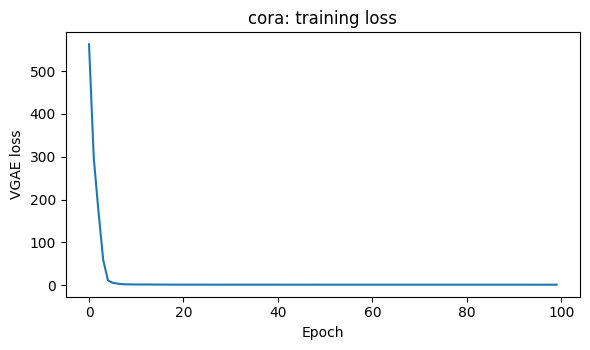

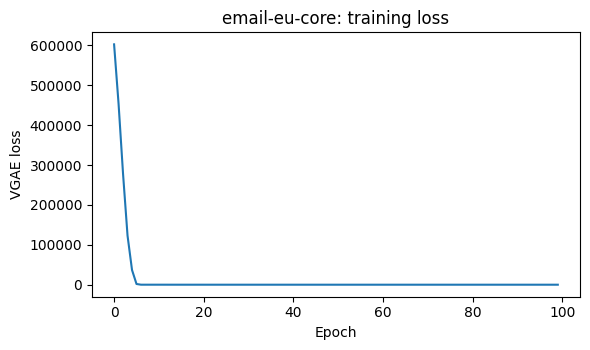

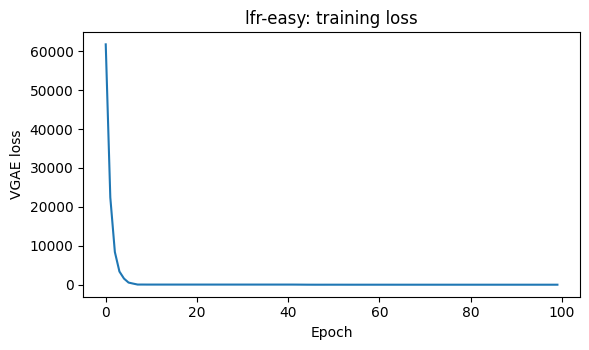

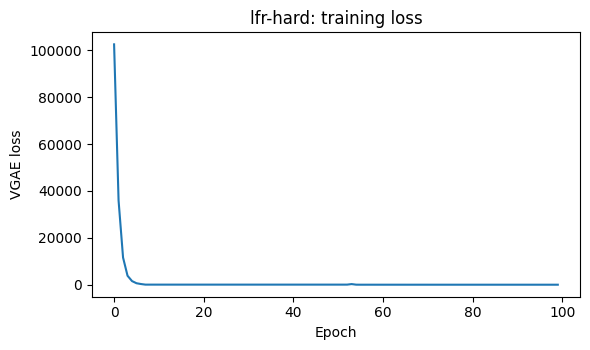

In [10]:

for key, history in baseline_histories.items():
    plt.figure(figsize=(6, 3.6))
    plt.plot(history)
    plt.xlabel("Epoch")
    plt.ylabel("VGAE loss")
    plt.title(f"{key}: training loss")
    plt.tight_layout()
    if SAVE_FIGURES:
        plt.savefig(Path(FIGURE_DIR) / f"{key}_training_loss.png", dpi=180, bbox_inches="tight")
    plt.show()


## 8. Clearer 3-D visualisation of the learned classification

We project each learned embedding to three dimensions with PCA and show:

- **ground truth communities**;
- **VGAE + KMeans predicted communities**, with cluster IDs aligned to the ground-truth IDs for visual comparability;
- a small inset summary of NMI, ARI, and matched accuracy in the figure title.

The plotted colours are therefore about visual correspondence, not the raw numerical KMeans IDs.


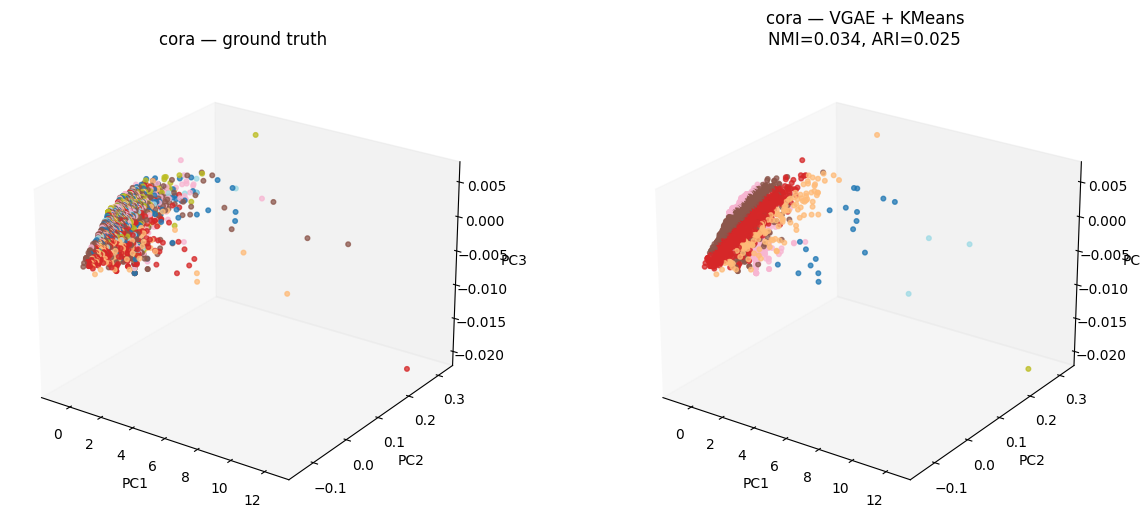

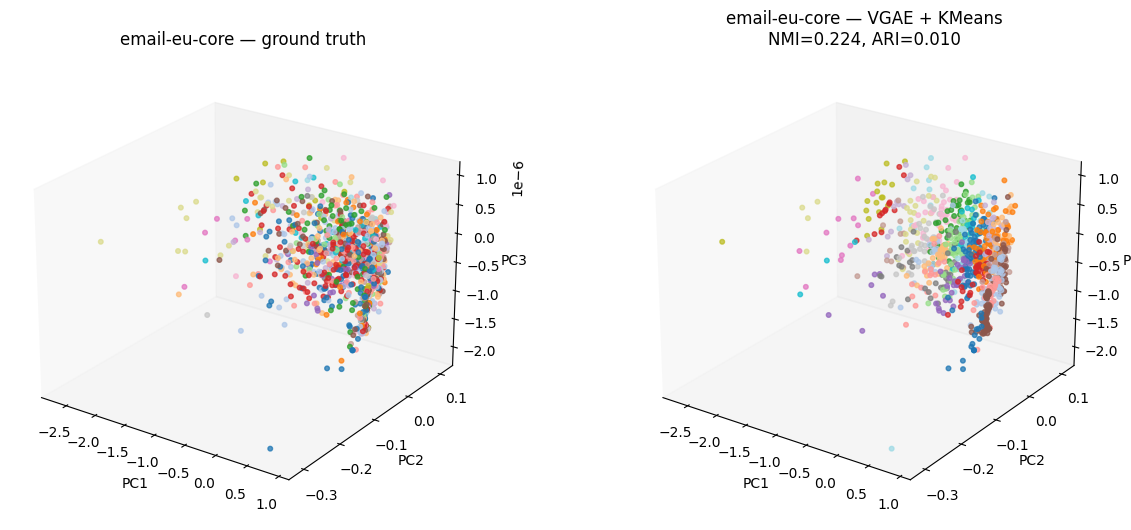

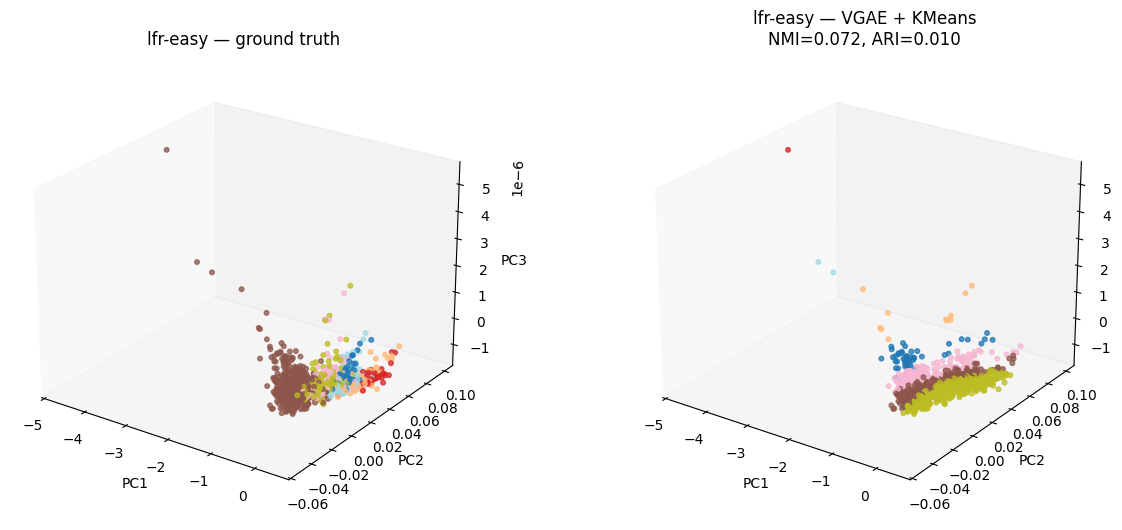

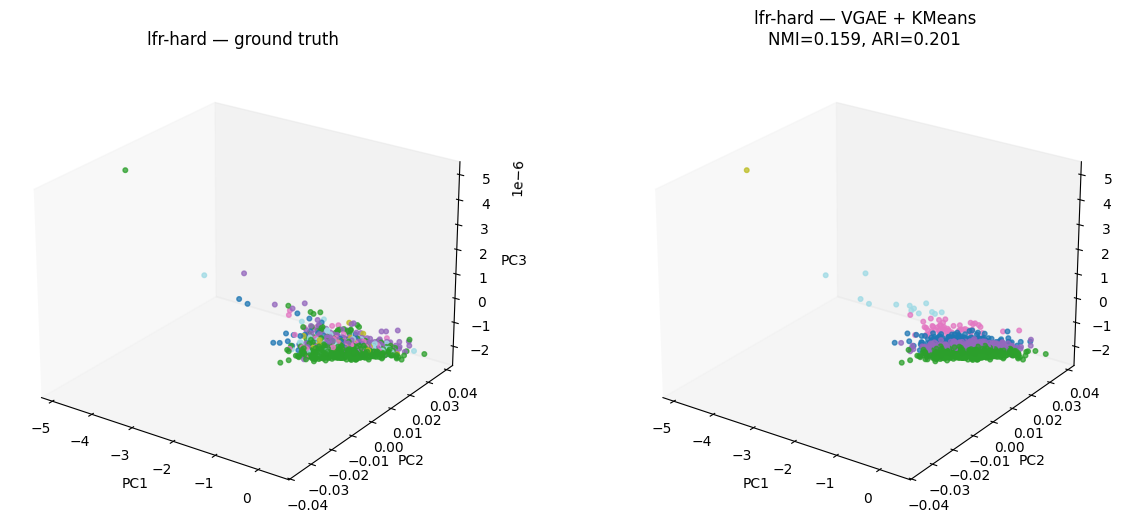

In [11]:

def project_to_3d(z, method="pca", seed=SEED):
    if z.shape[1] < 3:
        # Pad very low-dimensional embeddings so the plotting API still works.
        out = np.zeros((z.shape[0], 3), dtype=float)
        out[:, :z.shape[1]] = z
        return out

    if method == "pca":
        return PCA(n_components=3, random_state=seed).fit_transform(z)
    elif method == "tsne":
        return TSNE(
            n_components=3,
            random_state=seed,
            init="pca",
            learning_rate="auto",
        ).fit_transform(z)
    else:
        raise ValueError("method must be 'pca' or 'tsne'")


def plot_3d_classification(key, method=PROJECTION_METHOD, sample_limit=3000):
    z = baseline_embeddings[key]
    y = dataset_labels[key]
    y_pred = baseline_predictions[key]

    coords = project_to_3d(z, method=method)
    aligned_pred, _ = align_cluster_labels(y, y_pred)

    rng = np.random.default_rng(SEED)
    idx = np.arange(len(y))
    if len(idx) > sample_limit:
        idx = rng.choice(idx, size=sample_limit, replace=False)

    fig = plt.figure(figsize=(13, 5.4))
    axes = [
        fig.add_subplot(1, 2, 1, projection="3d"),
        fig.add_subplot(1, 2, 2, projection="3d"),
    ]

    # Ground truth
    sc0 = axes[0].scatter(
        coords[idx, 0], coords[idx, 1], coords[idx, 2],
        c=y[idx], cmap="tab20", s=11, alpha=0.75, depthshade=True
    )
    axes[0].set_title(f"{key} — ground truth")

    # Prediction aligned to true IDs for plotting only
    sc1 = axes[1].scatter(
        coords[idx, 0], coords[idx, 1], coords[idx, 2],
        c=aligned_pred[idx], cmap="tab20", s=11, alpha=0.75, depthshade=True
    )
    axes[1].set_title(
        f"{key} — VGAE + KMeans\n"
        f"NMI={baseline_df.loc[baseline_df.dataset.eq(key), 'NMI'].iloc[0]:.3f}, "
        f"ARI={baseline_df.loc[baseline_df.dataset.eq(key), 'ARI'].iloc[0]:.3f}"
    )

    for ax in axes:
        ax.set_xlabel("PC1")
        ax.set_ylabel("PC2")
        ax.set_zlabel("PC3")
        ax.grid(False)
        ax.view_init(elev=24, azim=-55)

    plt.tight_layout()
    if SAVE_FIGURES:
        plt.savefig(Path(FIGURE_DIR) / f"{key}_3d_classification.png", dpi=180, bbox_inches="tight")
    plt.show()


for key in LOADERS:
    plot_3d_classification(key)


## 9. Confusion-style cluster agreement view

The matrix below uses the same optimal predicted→true cluster alignment used in the 3-D plot. It highlights which ground-truth communities are being mixed together.

For community detection, this is often more interpretable than a raw KMeans confusion matrix because the original cluster IDs have no inherent ordering.


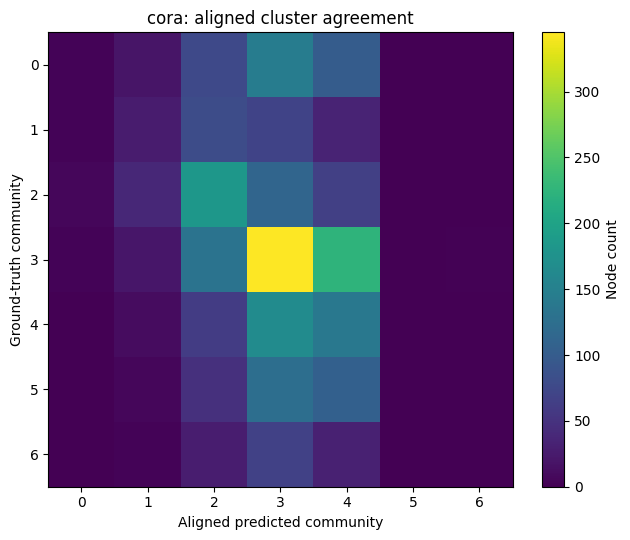

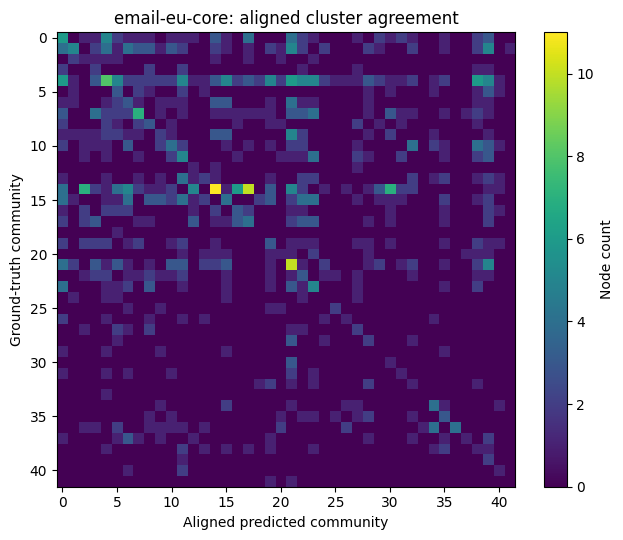

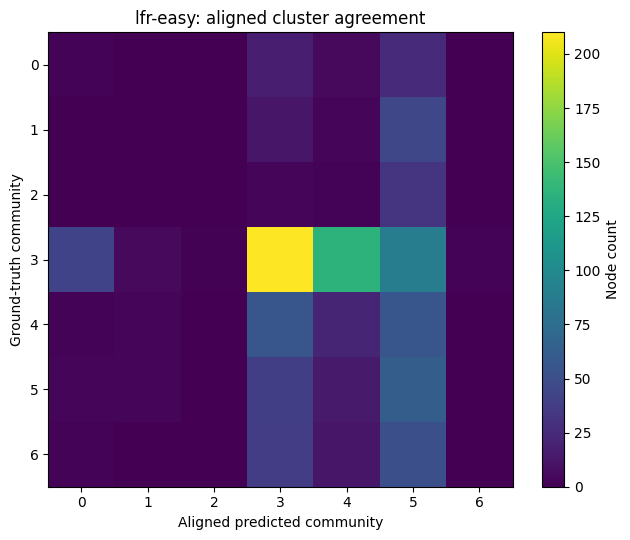

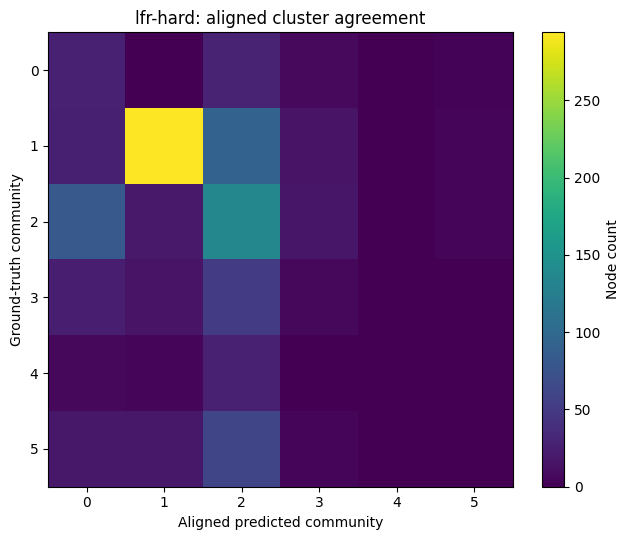

In [12]:

def plot_aligned_confusion(key):
    y = dataset_labels[key]
    y_pred = baseline_predictions[key]
    aligned, _ = align_cluster_labels(y, y_pred)

    mask = y >= 0
    labels = np.unique(y[mask])
    cm = confusion_matrix(y[mask], aligned[mask], labels=labels)

    plt.figure(figsize=(6.5, 5.5))
    plt.imshow(cm, aspect="auto")
    plt.colorbar(label="Node count")
    plt.xlabel("Aligned predicted community")
    plt.ylabel("Ground-truth community")
    plt.title(f"{key}: aligned cluster agreement")
    plt.tight_layout()
    if SAVE_FIGURES:
        plt.savefig(Path(FIGURE_DIR) / f"{key}_aligned_confusion.png", dpi=180, bbox_inches="tight")
    plt.show()


for key in LOADERS:
    plot_aligned_confusion(key)


## 10. Hyperparameter sweep: what different settings do

The sweep varies one parameter at a time while holding the others at baseline values.

Parameters tested:
- hidden dimension: **16 / 32 / 64**
- latent dimension: **8 / 16 / 32**
- learning rate: **0.005 / 0.01 / 0.02**
- KL weight: **0 / 0.1 / 1.0**
- dropout: **0 / 0.2 / 0.5**
- training epochs: **30 / 60 / 120**

The default target is `lfr-easy`; change `SWEEP_DATASET` above to test Cora, email-EU-core, or LFR-hard.

This is intentionally **one-factor-at-a-time**, not a full factorial grid, so the effects are easier to interpret and much cheaper to run.


In [13]:

def run_sweep():
    key = SWEEP_DATASET
    G = dataset_graphs[key]
    y = dataset_labels[key]

    configs = []

    for value in [16, 32, 64]:
        configs.append(("hidden", {"hidden": value}))
    for value in [8, 16, 32]:
        configs.append(("latent", {"latent": value}))
    for value in [0.005, 0.01, 0.02]:
        configs.append(("lr", {"lr": value}))
    for value in [0.0, 0.1, 1.0]:
        configs.append(("kl_weight", {"kl_weight": value}))
    for value in [0.0, 0.2, 0.5]:
        configs.append(("dropout", {"dropout": value}))
    for value in [30, 60, 120]:
        configs.append(("epochs", {"epochs": value}))

    records = []

    for factor, change in configs:
        for rep in range(SWEEP_REPEATS):
            data = datasets[key]
            params = dict(
                epochs=SWEEP_EPOCHS,
                lr=BASELINE_LR,
                hidden=BASELINE_HIDDEN,
                latent=BASELINE_LATENT,
                kl_weight=BASELINE_KL_WEIGHT,
                dropout=BASELINE_DROPOUT,
            )
            params.update(change)

            seed = SEED + rep
            print(f"{factor:10s}={change[factor]!s:>5s} | repeat {rep + 1}/{SWEEP_REPEATS}")

            metrics, _, _, _ = run_single_experiment(
                key, data, G, y,
                kmeans_n_init=KMEANS_N_INIT,
                seed=seed,
                feature_mode="native",
                experiment=f"sweep_{factor}",
                verbose=False,
                **params,
            )
            records.append(metrics)

    return pd.DataFrame(records)


if RUN_HYPERPARAMETER_SWEEP:
    sweep_df = run_sweep()
    sweep_df.to_csv("gnn_hyperparameter_sweep_cpu.csv", index=False)
    display(
        sweep_df[
            ["experiment", "dataset", "hidden", "latent", "lr", "kl_weight", "dropout",
             "epochs", "NMI", "ARI", "modularity", "matched_accuracy"]
        ].sort_values(["experiment", "NMI"], ascending=[True, False])
    )
    print("Saved: gnn_hyperparameter_sweep_cpu.csv")
else:
    sweep_df = pd.DataFrame()
    print("Hyperparameter sweep disabled.")


hidden    =   16 | repeat 1/1
hidden    =   32 | repeat 1/1
hidden    =   64 | repeat 1/1
latent    =    8 | repeat 1/1
latent    =   16 | repeat 1/1
latent    =   32 | repeat 1/1
lr        =0.005 | repeat 1/1
lr        = 0.01 | repeat 1/1
lr        = 0.02 | repeat 1/1
kl_weight =  0.0 | repeat 1/1
kl_weight =  0.1 | repeat 1/1
kl_weight =  1.0 | repeat 1/1
dropout   =  0.0 | repeat 1/1
dropout   =  0.2 | repeat 1/1
dropout   =  0.5 | repeat 1/1
epochs    =   30 | repeat 1/1
epochs    =   60 | repeat 1/1
epochs    =  120 | repeat 1/1


,experiment,dataset,hidden,latent,lr,kl_weight,dropout,epochs,NMI,ARI,modularity,matched_accuracy
12,sweep_dropout,lfr-easy,32,16,0.010,1.0,0.0,60,0.068340,0.009599,-0.010841,0.295
14,sweep_dropout,lfr-easy,32,16,0.010,1.0,0.5,60,0.063008,0.007834,-0.013672,0.295
13,sweep_dropout,lfr-easy,32,16,0.010,1.0,0.2,60,0.062791,-0.003844,-0.014422,0.300
16,sweep_epochs,lfr-easy,32,16,0.010,1.0,0.0,60,0.068340,0.009599,-0.010841,0.295
17,sweep_epochs,lfr-easy,32,16,0.010,1.0,0.0,120,0.068147,0.010119,-0.011153,0.297
15,sweep_epochs,lfr-easy,32,16,0.010,1.0,0.0,30,0.062516,0.006857,-0.013649,0.294
1,sweep_hidden,lfr-easy,32,16,0.010,1.0,0.0,60,0.068340,0.009599,-0.010841,0.295
2,sweep_hidden,lfr-easy,64,16,0.010,1.0,0.0,60,0.066925,0.011259,-0.011027,0.303
0,sweep_hidden,lfr-easy,16,16,0.010,1.0,0.0,60,0.064954,0.009832,-0.012155,0.302
11,sweep_kl_weight,lfr-easy,32,16,0.010,1.0,0.0,60,0.068340,0.009599,-0.010841,0.295


Saved: gnn_hyperparameter_sweep_cpu.csv


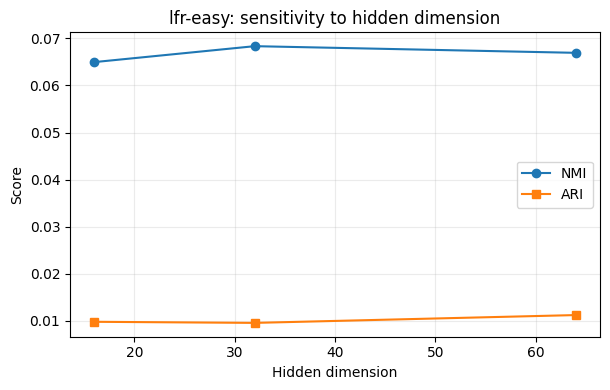

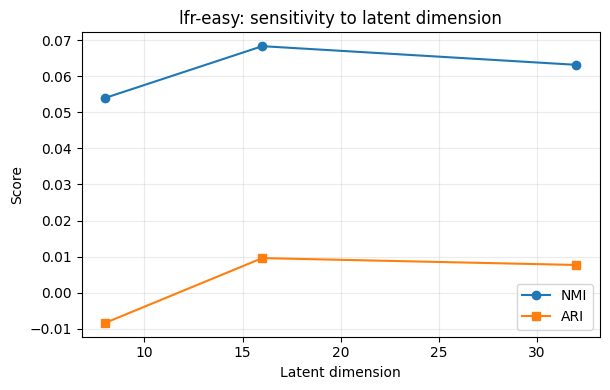

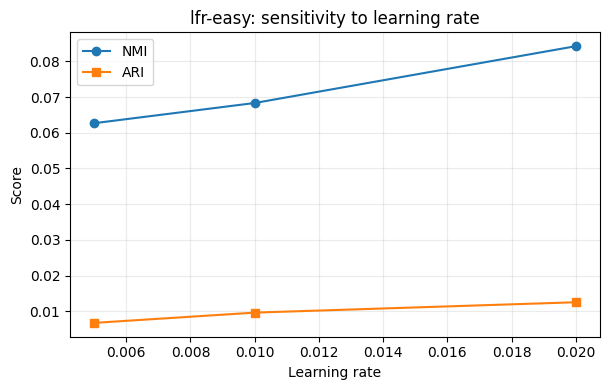

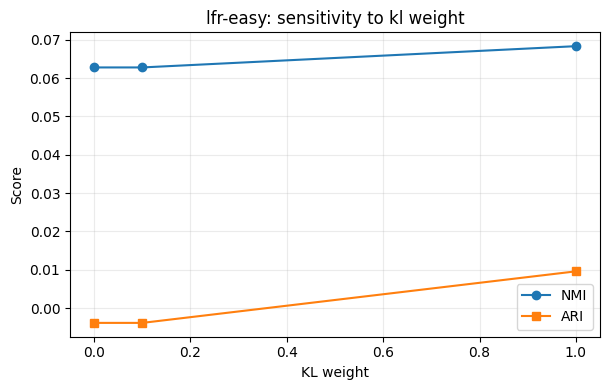

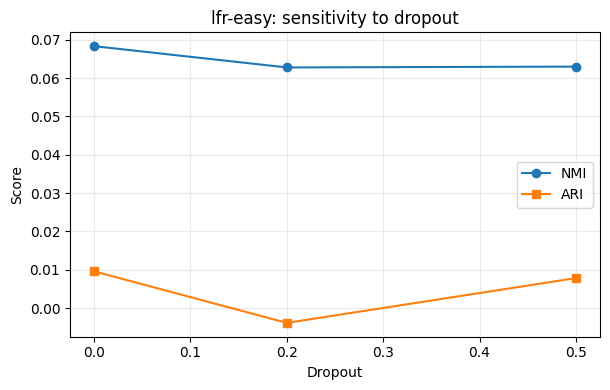

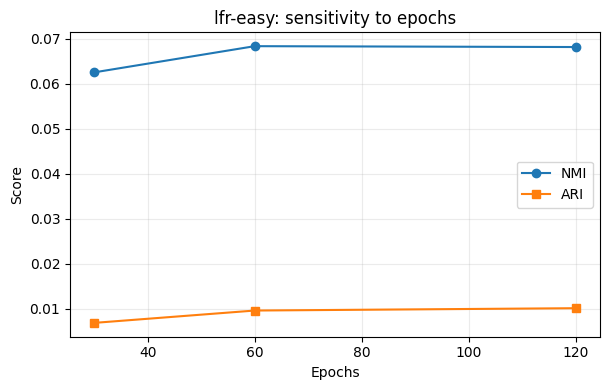

In [14]:

if RUN_HYPERPARAMETER_SWEEP and not sweep_df.empty:
    factor_specs = [
        ("hidden", "Hidden dimension", [16, 32, 64]),
        ("latent", "Latent dimension", [8, 16, 32]),
        ("lr", "Learning rate", [0.005, 0.01, 0.02]),
        ("kl_weight", "KL weight", [0.0, 0.1, 1.0]),
        ("dropout", "Dropout", [0.0, 0.2, 0.5]),
        ("epochs", "Epochs", [30, 60, 120]),
    ]

    for factor, label, values in factor_specs:
        sub = sweep_df[sweep_df["experiment"].eq(f"sweep_" + factor)].copy()
        # Average repeats, if any.
        sub = sub.groupby(factor, as_index=False)[["NMI", "ARI", "modularity"]].mean()
        sub = sub.sort_values(factor)

        plt.figure(figsize=(6.2, 4.0))
        plt.plot(sub[factor], sub["NMI"], marker="o", label="NMI")
        plt.plot(sub[factor], sub["ARI"], marker="s", label="ARI")
        plt.xlabel(label)
        plt.ylabel("Score")
        plt.title(f"{SWEEP_DATASET}: sensitivity to {label.lower()}")
        plt.grid(alpha=0.25)
        plt.legend()
        plt.tight_layout()
        if SAVE_FIGURES:
            plt.savefig(Path(FIGURE_DIR) / f"sweep_{factor}.png", dpi=180, bbox_inches="tight")
        plt.show()


## 11. Ablation study

The ablations ask more targeted questions than the hyperparameter sweep.

### A. No-KL ablation
Set `kl_weight=0`. This removes the variational regularisation while leaving the GCN encoder and reconstruction objective.

### B. Feature ablation
- `degree`: force every dataset to use degree only;
- `constant`: replace node features with a constant 1-D value, so the model cannot exploit degree differences directly.

### C. No-GNN feature baseline
Run KMeans directly on the input feature matrix. This does not perform message passing, so it tests whether the GNN embedding is providing additional clustering structure beyond the raw features supplied to it.

The no-GNN baseline is deliberately labelled as a **feature-only baseline**, not as a universal non-GNN community-detection baseline.


In [15]:

def kmeans_feature_baseline(key, feature_mode="native", seed=SEED):
    G, y, data = load_dataset(key, feature_mode=feature_mode)

    x = data.x.numpy()
    # Degree/Cora features can have very different scales; standardise when possible.
    # For sparse/high-dimensional Cora, use StandardScaler without centring.
    scaler = StandardScaler(with_mean=False)
    x_scaled = scaler.fit_transform(x)

    k = len(np.unique(y[y >= 0]))
    km = KMeans(n_clusters=k, n_init=KMEANS_N_INIT, random_state=seed)
    pred = km.fit_predict(x_scaled)

    metrics = evaluate_clustering(G, y, pred)
    metrics["matched_accuracy"] = matched_accuracy(y, pred)
    metrics.update({
        "dataset": key,
        "feature_mode": feature_mode,
        "experiment": "feature_only_kmeans",
        "seed": seed,
        "epochs": np.nan,
        "lr": np.nan,
        "hidden": np.nan,
        "latent": np.nan,
        "kl_weight": np.nan,
        "dropout": np.nan,
        "kmeans_n_init": KMEANS_N_INIT,
        "train_time_s": np.nan,
        "final_loss": np.nan,
    })
    return metrics


if RUN_ABLATION:
    ablation_records = []

    # GNN ablations for every dataset
    for key in LOADERS:
        G = dataset_graphs[key]
        y = dataset_labels[key]

        # A: remove KL regularisation
        metrics, _, _, _ = run_single_experiment(
            key, datasets[key], G, y,
            epochs=BASELINE_EPOCHS,
            lr=BASELINE_LR,
            hidden=BASELINE_HIDDEN,
            latent=BASELINE_LATENT,
            kl_weight=0.0,
            dropout=BASELINE_DROPOUT,
            kmeans_n_init=KMEANS_N_INIT,
            seed=SEED,
            feature_mode="native",
            experiment="ablation_no_kl",
            verbose=False,
        )
        ablation_records.append(metrics)

        # B1: degree-only features
        _, _, degree_data = load_dataset(key, feature_mode="degree")
        metrics, _, _, _ = run_single_experiment(
            key, degree_data, G, y,
            epochs=BASELINE_EPOCHS,
            lr=BASELINE_LR,
            hidden=BASELINE_HIDDEN,
            latent=BASELINE_LATENT,
            kl_weight=BASELINE_KL_WEIGHT,
            dropout=BASELINE_DROPOUT,
            kmeans_n_init=KMEANS_N_INIT,
            seed=SEED,
            feature_mode="degree",
            experiment="ablation_degree_features",
            verbose=False,
        )
        ablation_records.append(metrics)

        # B2: constant features
        _, _, constant_data = load_dataset(key, feature_mode="constant")
        metrics, _, _, _ = run_single_experiment(
            key, constant_data, G, y,
            epochs=BASELINE_EPOCHS,
            lr=BASELINE_LR,
            hidden=BASELINE_HIDDEN,
            latent=BASELINE_LATENT,
            kl_weight=BASELINE_KL_WEIGHT,
            dropout=BASELINE_DROPOUT,
            kmeans_n_init=KMEANS_N_INIT,
            seed=SEED,
            feature_mode="constant",
            experiment="ablation_constant_features",
            verbose=False,
        )
        ablation_records.append(metrics)

        # C: direct KMeans on supplied node features
        ablation_records.append(
            kmeans_feature_baseline(key, feature_mode="native", seed=SEED)
        )

    ablation_df = pd.DataFrame(ablation_records)
    ablation_df.to_csv("gnn_ablation_cpu.csv", index=False)

    display(
        ablation_df[
            ["dataset", "experiment", "feature_mode", "NMI", "ARI",
             "modularity", "matched_accuracy"]
        ].sort_values(["dataset", "experiment"])
    )
    print("Saved: gnn_ablation_cpu.csv")
else:
    ablation_df = pd.DataFrame()
    print("Ablation study disabled.")


C:\Users\josqu\AppData\Local\Temp\ipykernel_26432\3703914001.py:6: DeprecationWarning: Please import `csr_matrix` from the `scipy.sparse` namespace; the `scipy.sparse.csr` namespace is deprecated and will be removed in SciPy 2.0.0.
  allx = pkl.load(f, encoding="latin1")
C:\Users\josqu\AppData\Local\Temp\ipykernel_26432\3703914001.py:8: DeprecationWarning: Please import `csr_matrix` from the `scipy.sparse` namespace; the `scipy.sparse.csr` namespace is deprecated and will be removed in SciPy 2.0.0.
  tx = pkl.load(f, encoding="latin1")


,dataset,experiment,feature_mode,NMI,ARI,modularity,matched_accuracy
2,cora,ablation_constant_features,constant,0.005372,0.001981,-0.029623,0.216901
1,cora,ablation_degree_features,degree,0.034087,0.025115,0.063135,0.279678
0,cora,ablation_no_kl,native,0.037418,0.022330,0.074695,0.255131
3,cora,feature_only_kmeans,native,0.006030,0.009881,-0.020131,0.258753
6,email-eu-core,ablation_constant_features,constant,0.214401,0.006247,0.001210,0.115619
5,email-eu-core,ablation_degree_features,degree,0.224313,0.009867,0.007954,0.123732
4,email-eu-core,ablation_no_kl,native,0.212859,0.006728,0.001054,0.118661
7,email-eu-core,feature_only_kmeans,native,0.203124,0.006491,0.000257,0.118661
10,lfr-easy,ablation_constant_features,constant,0.017947,0.003246,-0.023057,0.279000
9,lfr-easy,ablation_degree_features,degree,0.071916,0.010475,-0.009796,0.296000


Saved: gnn_ablation_cpu.csv


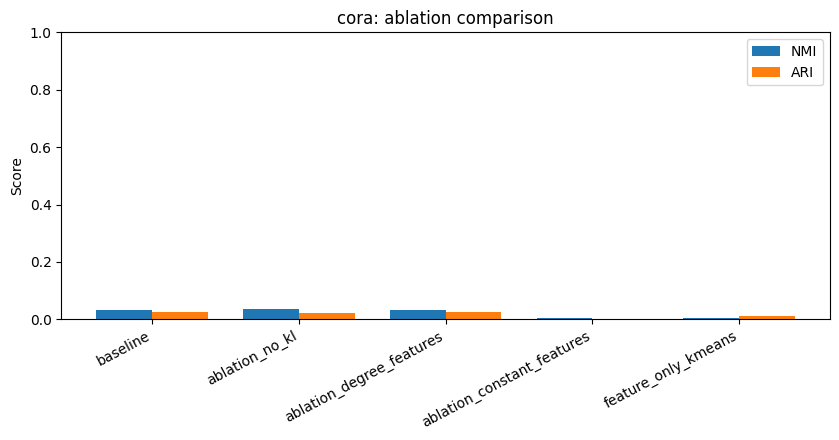

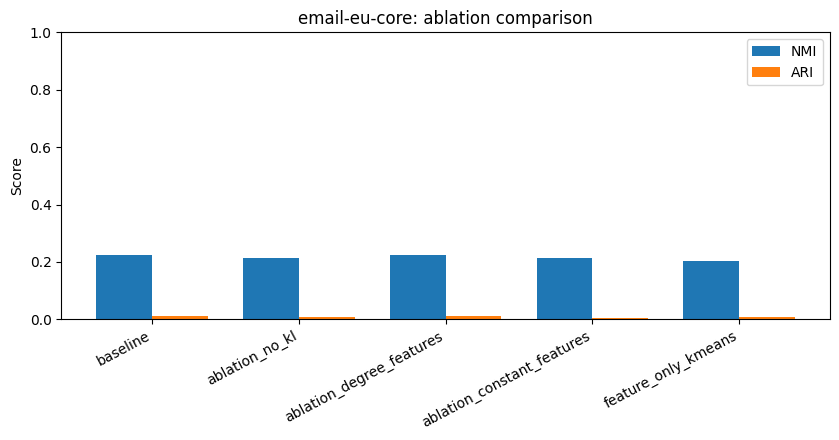

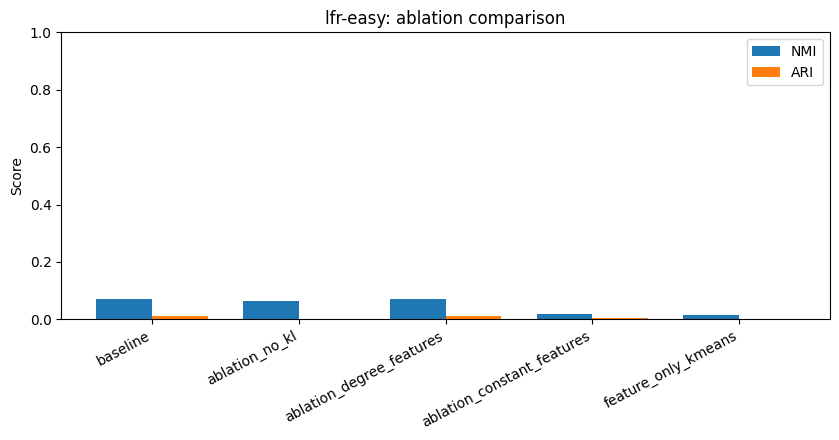

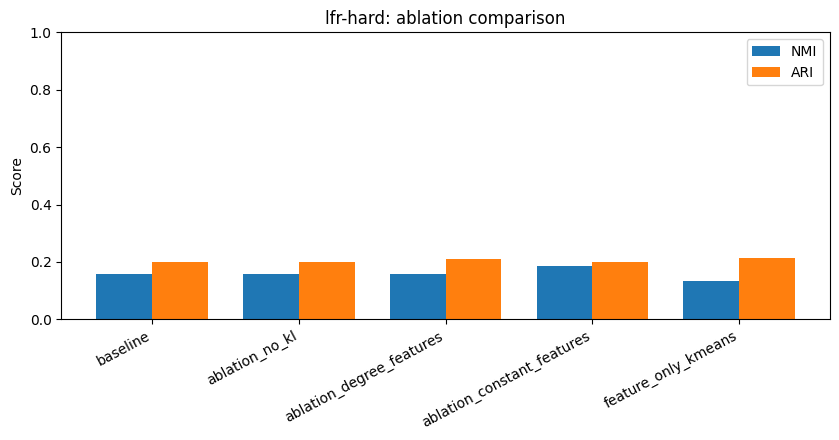

In [16]:

if RUN_ABLATION and not ablation_df.empty:
    for key in LOADERS:
        sub = ablation_df[ablation_df["dataset"].eq(key)].copy()

        # Add the main baseline for direct comparison.
        b = baseline_df[baseline_df["dataset"].eq(key)].iloc[0]
        baseline_row = pd.DataFrame([{
            "dataset": key,
            "experiment": "baseline",
            "feature_mode": b["feature_mode"],
            "NMI": b["NMI"],
            "ARI": b["ARI"],
            "modularity": b["modularity"],
            "matched_accuracy": b["matched_accuracy"],
        }])

        plot_df = pd.concat([
            baseline_row,
            sub[["dataset", "experiment", "feature_mode", "NMI", "ARI", "modularity", "matched_accuracy"]]
        ], ignore_index=True)

        x = np.arange(len(plot_df))
        width = 0.38

        plt.figure(figsize=(8.5, 4.5))
        plt.bar(x - width/2, plot_df["NMI"], width, label="NMI")
        plt.bar(x + width/2, plot_df["ARI"], width, label="ARI")
        plt.xticks(x, plot_df["experiment"], rotation=28, ha="right")
        plt.ylim(0, 1)
        plt.ylabel("Score")
        plt.title(f"{key}: ablation comparison")
        plt.legend()
        plt.tight_layout()
        if SAVE_FIGURES:
            plt.savefig(Path(FIGURE_DIR) / f"{key}_ablation.png", dpi=180, bbox_inches="tight")
        plt.show()


## 12. Parameter interpretation guide

Use the sweep to make dataset-specific claims, but the following interpretations explain what each parameter changes:

| Parameter | What changes | Typical risk when too low | Typical risk when too high |
|---|---|---|---|
| `hidden` | Capacity of the intermediate GCN representation | underfitting / insufficient local information | unnecessary computation / overfitting |
| `latent` | Size of the node embedding | compressed information bottleneck | noisy/redundant embedding space |
| `lr` | Optimiser step size | very slow learning | unstable or oscillating training |
| `epochs` | Optimisation budget | under-trained embedding | extra runtime with little clustering gain |
| `kl_weight` | Strength of variational regularisation | less constrained latent distribution when near 0 | too much pressure toward a simple latent distribution |
| `dropout` | Regularisation of hidden representations | no regularisation | underfitting when excessive |
| `KMeans n_init` | Number of centroid initialisations | more seed sensitivity | more clustering compute, usually more stable KMeans |

A particularly important distinction is **training loss vs clustering quality**: a parameter can improve edge reconstruction without improving NMI/ARI because the VGAE objective and community labels are not identical objectives.


## 13. Report-ready analysis: key factors affecting performance

After running the notebook, the next cell prints a compact interpretation that uses the actual measured baseline/sweep/ablation results.

The most important factors to discuss in the final report are:

1. **Community separability / graph structure.** LFR's mixing level (`mu`) changes how strongly community membership is reflected in the graph. Harder mixing generally makes graph-based recovery more difficult, but the direction and magnitude should be stated from the measured NMI/ARI rather than assumed.
2. **Node feature informativeness.** Cora has semantic/text features; the other datasets use degree as a fallback. The feature ablations directly test how much performance changes when those inputs are removed or simplified.
3. **Latent capacity.** Hidden and latent dimensions determine how much information the encoder can preserve. Too little capacity can compress useful structure; excess capacity can add noise and computation.
4. **Optimisation settings.** Learning rate and epochs determine whether the VGAE reaches a useful representation. Always compare both final loss and clustering metrics.
5. **Regularisation.** The KL term controls the variational constraint. The no-KL ablation tests whether that constraint helps the clustering objective on these datasets.
6. **Clustering step.** KMeans adds its own sensitivity through `K` and centroid initialisation. Because `K` is fixed to the true community count here, KMeans is not a fully unsupervised community-count estimation method.
7. **Randomness.** VGAE sampling, parameter initialisation, and KMeans initialisation can move the result. For a polished report, multiple seeds and mean ± standard deviation are preferable.


In [17]:

def print_report_analysis():
    print("=" * 80)
    print("REPORT-READY BASELINE ANALYSIS")
    print("=" * 80)

    # Baseline observations
    by_nmi = baseline_df.sort_values("NMI", ascending=False)
    by_ari = baseline_df.sort_values("ARI", ascending=False)

    print("\nBaseline results:")
    display(
        baseline_df[
            ["dataset", "NMI", "ARI", "modularity", "matched_accuracy", "train_time_s"]
        ].style.format({
            "NMI": "{:.3f}",
            "ARI": "{:.3f}",
            "modularity": "{:.3f}",
            "matched_accuracy": "{:.3f}",
            "train_time_s": "{:.1f}",
        })
    )

    print("\nObserved baseline spread:")
    print(
        f"NMI spans {baseline_df['NMI'].min():.3f} to {baseline_df['NMI'].max():.3f}; "
        f"ARI spans {baseline_df['ARI'].min():.3f} to {baseline_df['ARI'].max():.3f}."
    )
    print(
        "This variation means dataset structure and feature quality should be discussed alongside "
        "hyperparameters rather than treating the GNN as having one universal performance level."
    )

    if RUN_HYPERPARAMETER_SWEEP and not sweep_df.empty:
        print(f"\nHyperparameter sensitivity on {SWEEP_DATASET}:")
        for factor in ["hidden", "latent", "lr", "kl_weight", "dropout", "epochs"]:
            sub = sweep_df[sweep_df["experiment"].eq("sweep_" + factor)].copy()
            agg = sub.groupby(factor, as_index=False)[["NMI", "ARI"]].mean()
            nmi_range = agg["NMI"].max() - agg["NMI"].min()
            ari_range = agg["ARI"].max() - agg["ARI"].min()
            print(f"  {factor:10s}: NMI range={nmi_range:.3f}, ARI range={ari_range:.3f}")

        # Identify the strongest measured one-factor effect by NMI range.
        ranges = []
        for factor in ["hidden", "latent", "lr", "kl_weight", "dropout", "epochs"]:
            sub = sweep_df[sweep_df["experiment"].eq("sweep_" + factor)]
            if len(sub):
                agg = sub.groupby(factor)["NMI"].mean()
                ranges.append((factor, float(agg.max() - agg.min())))
        if ranges:
            ranges.sort(key=lambda x: x[1], reverse=True)
            print(
                f"  Largest measured one-factor NMI swing: {ranges[0][0]} "
                f"({ranges[0][1]:.3f}) on {SWEEP_DATASET}."
            )

    if RUN_ABLATION and not ablation_df.empty:
        print("\nAblation observations:")
        for key in LOADERS:
            b = float(baseline_df.loc[baseline_df.dataset.eq(key), "NMI"].iloc[0])
            sub = ablation_df[ablation_df.dataset.eq(key)].copy()
            print(f"  {key}: baseline NMI={b:.3f}")

            for exp in [
                "ablation_no_kl",
                "ablation_degree_features",
                "ablation_constant_features",
                "feature_only_kmeans",
            ]:
                match = sub[sub.experiment.eq(exp)]
                if len(match):
                    val = float(match["NMI"].iloc[0])
                    print(f"    {exp:28s} NMI={val:.3f} | delta={val - b:+.3f}")

    print("\nHow to phrase the conclusion:")
    print(
        "Use the measured deltas to identify which factors were influential on the supplied datasets. "
        "Avoid claiming that a parameter is universally best; report the tested range, dataset, "
        "number of runs, and variability."
    )

print_report_analysis()


REPORT-READY BASELINE ANALYSIS

Baseline results:


,dataset,NMI,ARI,modularity,matched_accuracy,train_time_s
0,cora,0.034,0.025,0.063,0.280,4.0
1,email-eu-core,0.224,0.010,0.008,0.124,9.5
2,lfr-easy,0.072,0.010,-0.010,0.296,4.7
3,lfr-hard,0.159,0.201,-0.040,0.464,4.7



Observed baseline spread:
NMI spans 0.034 to 0.224; ARI spans 0.010 to 0.201.
This variation means dataset structure and feature quality should be discussed alongside hyperparameters rather than treating the GNN as having one universal performance level.

Hyperparameter sensitivity on lfr-easy:
  hidden    : NMI range=0.003, ARI range=0.002
  latent    : NMI range=0.014, ARI range=0.018
  lr        : NMI range=0.022, ARI range=0.006
  kl_weight : NMI range=0.006, ARI range=0.013
  dropout   : NMI range=0.006, ARI range=0.013
  epochs    : NMI range=0.006, ARI range=0.003
  Largest measured one-factor NMI swing: lr (0.022) on lfr-easy.

Ablation observations:
  cora: baseline NMI=0.034
    ablation_no_kl               NMI=0.037 | delta=+0.003
    ablation_degree_features     NMI=0.034 | delta=+0.000
    ablation_constant_features   NMI=0.005 | delta=-0.029
    feature_only_kmeans          NMI=0.006 | delta=-0.028
  email-eu-core: baseline NMI=0.224
    ablation_no_kl               NMI=

## 14. Combined results and files produced

The notebook writes:

- `gnn_results_cpu.csv` — original-compatible baseline table;
- `gnn_baseline_extended_cpu.csv` — baseline plus all hyperparameters;
- `gnn_hyperparameter_sweep_cpu.csv` — one-factor-at-a-time parameter results;
- `gnn_ablation_cpu.csv` — ablation results;
- `gnn_graph_stats_cpu.csv` — graph/data characteristics;
- `gnn_figures/` — training curves, 3-D classification plots, aligned confusion-style plots, sweep plots, and ablation plots.

For the final report, use the baseline table for the main GNN-vs-Louvain/Leiden comparison, and use the extended CSVs to support the methodology/ablation discussion.


In [18]:

# Combine all experiment tables into one convenient export.
combined_parts = [baseline_df.copy()]

if RUN_HYPERPARAMETER_SWEEP and not sweep_df.empty:
    combined_parts.append(sweep_df.copy())

if RUN_ABLATION and not ablation_df.empty:
    combined_parts.append(ablation_df.copy())

combined_df = pd.concat(combined_parts, ignore_index=True, sort=False)
combined_df.to_csv("gnn_all_experiments_cpu.csv", index=False)

display(combined_df.head())
print(f"Saved {len(combined_df)} experiment rows to gnn_all_experiments_cpu.csv")


,dataset,n_nodes,n_clusters,NMI,ARI,modularity,matched_accuracy,train_time_s,epochs,lr,hidden,latent,kl_weight,dropout,kmeans_n_init,feature_mode,seed,experiment,final_loss
0,cora,2485.0,7.0,0.034087,0.025115,0.063135,0.279678,4.04,100.0,0.01,32.0,16.0,1.0,0.0,10,native,NaN,NaN,NaN
1,email-eu-core,986.0,42.0,0.224313,0.009867,0.007954,0.123732,9.48,100.0,0.01,32.0,16.0,1.0,0.0,10,native,NaN,NaN,NaN
2,lfr-easy,1000.0,7.0,0.071916,0.010475,-0.009796,0.296000,4.65,100.0,0.01,32.0,16.0,1.0,0.0,10,native,NaN,NaN,NaN
3,lfr-hard,1000.0,6.0,0.159190,0.201292,-0.039780,0.464000,4.65,100.0,0.01,32.0,16.0,1.0,0.0,10,native,NaN,NaN,NaN
4,lfr-easy,1000.0,7.0,0.064954,0.009832,-0.012155,0.302000,2.87,60.0,0.01,16.0,16.0,1.0,0.0,10,native,67.0,sweep_hidden,1.544787


Saved 38 experiment rows to gnn_all_experiments_cpu.csv
